In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 중고차 데이터 불러오기
df = pd.read_csv("used_cars.csv")

# 데이터 크기 확인
print("데이터 크기:", df.shape)

# 데이터 앞부분 확인
display(df.head())

# 결측치 확인
print("\n결측치 개수:")
print(df.isnull().sum())


데이터 크기: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"



결측치 개수:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [6]:

# 가격 데이터 숫자로 변환
df['price'] = df['price'].replace(
    r'[\$,]', '', regex=True
).astype(float)

# 주행거리 데이터 숫자로 변환
df['milage'] = df['milage'].replace(
    r'[^0-9.]', '', regex=True
).astype(float)

# 결측치 처리
df['fuel_type'] = df['fuel_type'].fillna('Unknown')
df['accident'] = df['accident'].fillna('Unknown')
df['clean_title'] = df['clean_title'].fillna('Unknown')

# 전처리 결과 확인
print("전처리 완료!")
print(df[['price', 'milage']].head())
print("\n남은 결측치:")
print(df.isnull().sum())


전처리 완료!
     price   milage
0  10300.0  51000.0
1  38005.0  34742.0
2  54598.0  22372.0
3  15500.0  88900.0
4  34999.0   9835.0

남은 결측치:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64


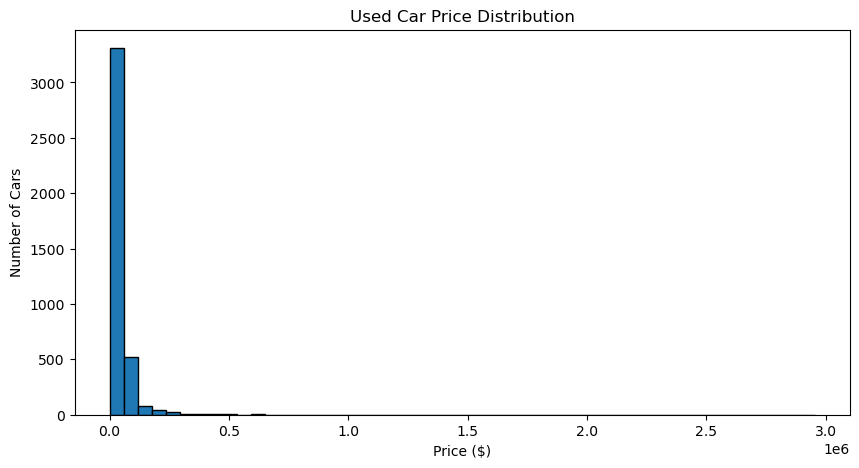

count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price, dtype: float64


In [8]:

# 중고차 가격 분포
plt.figure(figsize=(10, 5))

plt.hist(df['price'], bins=50, edgecolor='black')

plt.title('Used Car Price Distribution')
plt.xlabel('Price ($)')
plt.ylabel('Number of Cars')

plt.show()

# 가격 통계 확인
print(df['price'].describe())


In [10]:

# 가격 이상치 분석 (IQR 방법)

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("이상치 상한:", upper_bound)

# 이상치 개수 확인
outliers = df[
    (df['price'] < lower_bound) |
    (df['price'] > upper_bound)
]

print("이상치 개수:", len(outliers))
print("이상치 비율:", round(len(outliers) / len(df) * 100, 2), "%")

# 가격이 높은 차량 10개 확인
display(df.nlargest(10, 'price')[
    ['brand', 'model', 'model_year', 'milage', 'price']
])


Q1: 17200.0
Q3: 49990.0
IQR: 32790.0
이상치 상한: 99175.0
이상치 개수: 244
이상치 비율: 6.09 %


,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,1950995.0
3046,Porsche,Carrera GT Base,2005,4400.0,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,6987.0,749950.0
624,Rolls-Royce,Cullinan,2022,398.0,695000.0
979,Lamborghini,Aventador SVJ Base,2019,6929.0,649999.0
1615,Rolls-Royce,Phantom,2023,1560.0,599995.0
1508,Rolls-Royce,Phantom,2018,7585.0,599000.0
3655,Lamborghini,Aventador S Base,2018,5858.0,491836.0
1061,Dodge,Viper GTC,2017,1389.0,489995.0


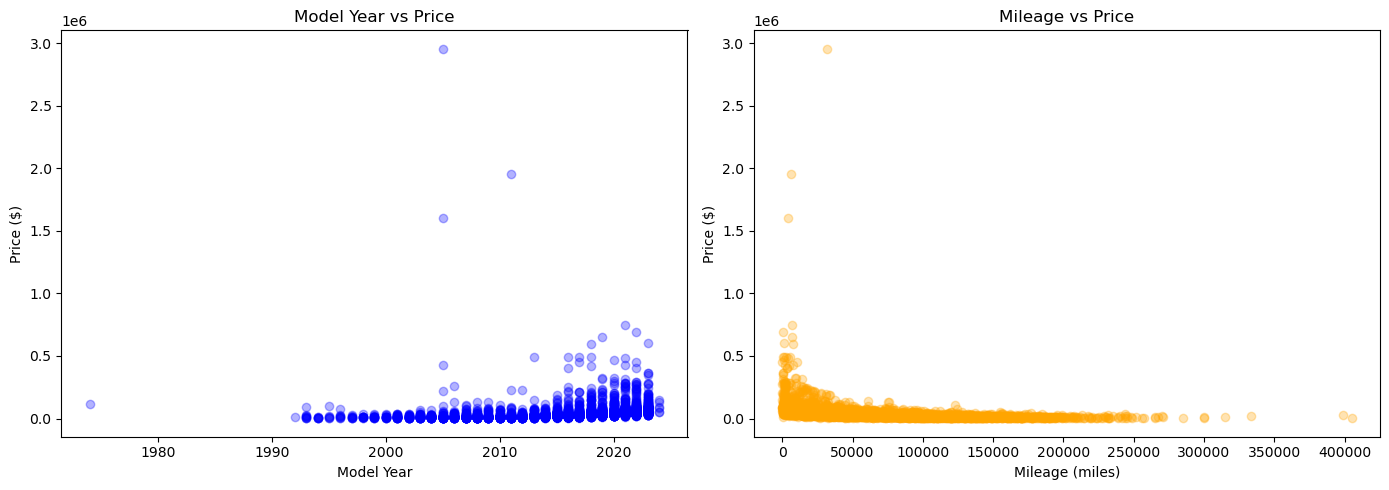

In [12]:

# 연식과 주행거리에 따른 가격 분석

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 연식과 가격 관계
axes[0].scatter(
    df['model_year'],
    df['price'],
    alpha=0.3,
    color='blue'
)

axes[0].set_title('Model Year vs Price')
axes[0].set_xlabel('Model Year')
axes[0].set_ylabel('Price ($)')

# 주행거리와 가격 관계
axes[1].scatter(
    df['milage'],
    df['price'],
    alpha=0.3,
    color='orange'
)

axes[1].set_title('Mileage vs Price')
axes[1].set_xlabel('Mileage (miles)')
axes[1].set_ylabel('Price ($)')

plt.tight_layout()
plt.show()


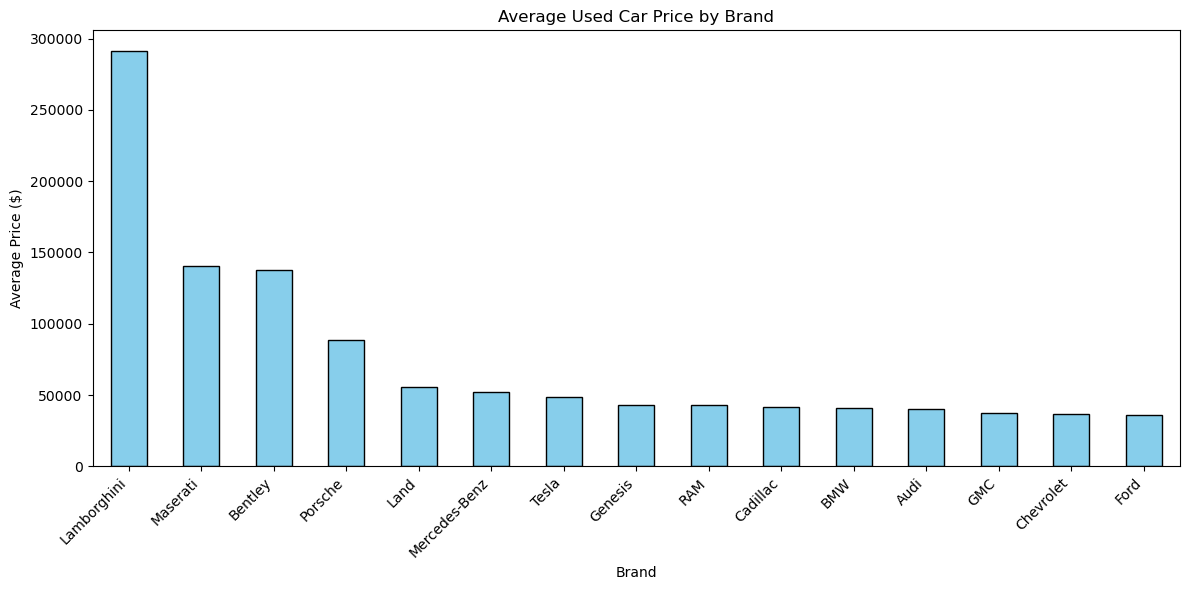

brand
Lamborghini      291233.846154
Maserati         140582.529412
Bentley          137553.545455
Porsche           88751.298507
Land              55764.061538
Mercedes-Benz     52075.765079
Tesla             48439.471264
Genesis           43279.900000
RAM               43029.164835
Cadillac          41670.728972
BMW               41072.309333
Audi              39907.430000
GMC               37525.681319
Chevrolet         36722.739726
Ford              36240.880829
Name: price, dtype: float64


In [14]:

# 브랜드별 차량 수 확인
brand_counts = df['brand'].value_counts()

# 차량이 20대 이상인 브랜드만 선택
selected_brands = brand_counts[
    brand_counts >= 20
].index

# 브랜드별 평균 가격 계산
brand_prices = (
    df[df['brand'].isin(selected_brands)]
    .groupby('brand')['price']
    .mean()
    .sort_values(ascending=False)
)

# 상위 15개 브랜드 시각화
plt.figure(figsize=(12, 6))

brand_prices.head(15).plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Average Used Car Price by Brand')
plt.xlabel('Brand')
plt.ylabel('Average Price ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 분석 결과 출력
print(brand_prices.head(15))


In [16]:

from sklearn.model_selection import train_test_split

# 머신러닝에 사용할 변수 선택
features = [
    'brand',
    'model_year',
    'milage',
    'fuel_type',
    'transmission',
    'accident'
]

X = df[features].copy()
y = df['price'].copy()

# 학습 데이터 70%, 나머지 30%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# 검증 15%, 테스트 15%
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("학습 데이터:", X_train.shape)
print("검증 데이터:", X_val.shape)
print("테스트 데이터:", X_test.shape)


학습 데이터: (2806, 6)
검증 데이터: (601, 6)
테스트 데이터: (602, 6)


In [18]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# 숫자형 변수
numeric_features = ['model_year', 'milage']

# 범주형 변수
categorical_features = [
    'brand', 'fuel_type', 'transmission', 'accident'
]

# 숫자형 전처리
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# 범주형 전처리
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(
        strategy='most_frequent'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

# 전체 전처리 구성
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("머신러닝 전처리 준비 완료!")


머신러닝 전처리 준비 완료!


In [20]:

# Random Forest 모델 생성
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# 직접 모델 학습
rf_model.fit(X_train, y_train)

print("Random Forest 모델 학습 완료!")


Random Forest 모델 학습 완료!


In [22]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 검증 데이터 가격 예측
rf_pred = rf_model.predict(X_val)

# 성능 평가
rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))
rf_r2 = r2_score(y_val, rf_pred)

print("Random Forest 성능 평가")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2:", round(rf_r2, 4))


Random Forest 성능 평가
MAE: 13859.36
RMSE: 30946.91
R2: 0.5938


In [24]:

# XGBoost 설치 (처음 한 번만)
%pip install xgboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 7.2 MB/s eta 0:00:004 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [26]:

from xgboost import XGBRegressor

print("XGBoost 준비 완료!")


XGBoost 준비 완료!


In [28]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline

# XGBoost 모델 생성
xgb_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('regressor', XGBRegressor(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    ))
])

# 직접 머신러닝 학습
xgb_model.fit(X_train, y_train)

print("XGBoost 모델 학습 완료!")


XGBoost 모델 학습 완료!


In [30]:

# 검증 데이터 예측
xgb_pred = xgb_model.predict(X_val)

# 성능 계산
xgb_mae = mean_absolute_error(y_val, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_pred))
xgb_r2 = r2_score(y_val, xgb_pred)

print("XGBoost 성능 평가")
print("MAE:", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("R2:", round(xgb_r2, 4))


XGBoost 성능 평가
MAE: 14551.03
RMSE: 31007.05
R2: 0.5922


In [32]:

# 모델별 성능 비교
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'MAE': [rf_mae, xgb_mae],
    'RMSE': [rf_rmse, xgb_rmse],
    'R2': [rf_r2, xgb_r2]
})

display(results.round(2))


,Model,MAE,RMSE,R2
0,Random Forest,13859.36,30946.91,0.59
1,XGBoost,14551.03,31007.05,0.59


In [34]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

# Random Forest 하이퍼파라미터 후보
param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__max_depth': [10, 20, None],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [1, 2, 4]
}

# 랜덤 탐색 및 교차검증
rf_search = RandomizedSearchCV(
    estimator=clone(rf_model),
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

# 학습 데이터로 직접 최적화
rf_search.fit(X_train, y_train)

print("최적 파라미터:")
print(rf_search.best_params_)

print("교차검증 MAE:",
      round(-rf_search.best_score_, 2))


최적 파라미터:
{'regressor__n_estimators': 100, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 1, 'regressor__max_depth': 20}
교차검증 MAE: 14081.01


In [36]:

# 최적화 모델의 검증 데이터 예측
rf_tuned = rf_search.best_estimator_
rf_tuned_pred = rf_tuned.predict(X_val)

rf_tuned_mae = mean_absolute_error(
    y_val, rf_tuned_pred
)

rf_tuned_rmse = np.sqrt(
    mean_squared_error(y_val, rf_tuned_pred)
)

rf_tuned_r2 = r2_score(
    y_val, rf_tuned_pred
)

comparison = pd.DataFrame({
    'Model': ['Original RF', 'Tuned RF'],
    'MAE': [rf_mae, rf_tuned_mae],
    'RMSE': [rf_rmse, rf_tuned_rmse],
    'R2': [rf_r2, rf_tuned_r2]
})

display(comparison.round(4))


,Model,MAE,RMSE,R2
0,Original RF,13859.3642,30946.9072,0.5938
1,Tuned RF,13875.3481,29654.6667,0.6270


,Feature,Importance
2,milage,10723.742062
0,brand,6440.481267
1,model_year,4603.283993
4,transmission,1086.322561
3,fuel_type,486.948891
5,accident,14.391601


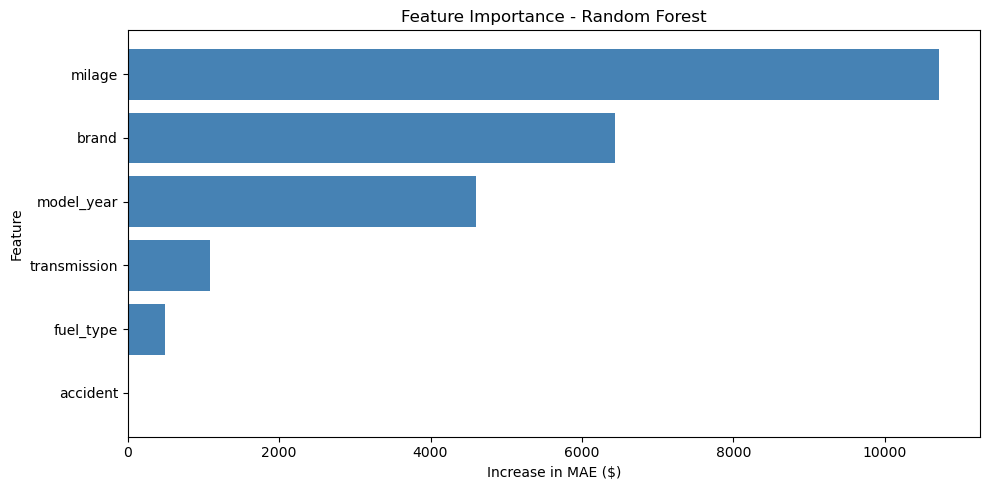

In [38]:

from sklearn.inspection import permutation_importance

# 최적화된 모델의 변수 중요도 분석
importance = permutation_importance(
    rf_tuned,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# 변수별 중요도 정리
importance_df = pd.DataFrame({
    'Feature': X_val.columns,
    'Importance': importance.importances_mean
}).sort_values('Importance', ascending=False)

display(importance_df)

# 그래프 출력
plt.figure(figsize=(10, 5))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color='steelblue'
)

plt.gca().invert_yaxis()
plt.title('Feature Importance - Random Forest')
plt.xlabel('Increase in MAE ($)')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


In [40]:

%pip install shap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 9.5 MB/s eta 0:00:009.4 MB/s eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.2.6 which is incompatible.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.2.6 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.6 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [42]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# 학습된 전처리기와 모델 가져오기
fitted_preprocessor = rf_tuned.named_steps['preprocessor']
fitted_rf = rf_tuned.named_steps['regressor']

# 검증 데이터 중 30개만 사용
X_sample = X_val.sample(n=30, random_state=42)

# 학습된 전처리기로 변환
X_sample_transformed = fitted_preprocessor.transform(X_sample)

# SHAP 계산을 위해 배열 변환
if hasattr(X_sample_transformed, 'toarray'):
    X_sample_transformed = X_sample_transformed.toarray()

# 변환된 변수 이름
feature_names = fitted_preprocessor.get_feature_names_out()

print("SHAP 분석 데이터 준비 완료!")
print("데이터 크기:", X_sample_transformed.shape)


SHAP 분석 데이터 준비 완료!
데이터 크기: (30, 129)


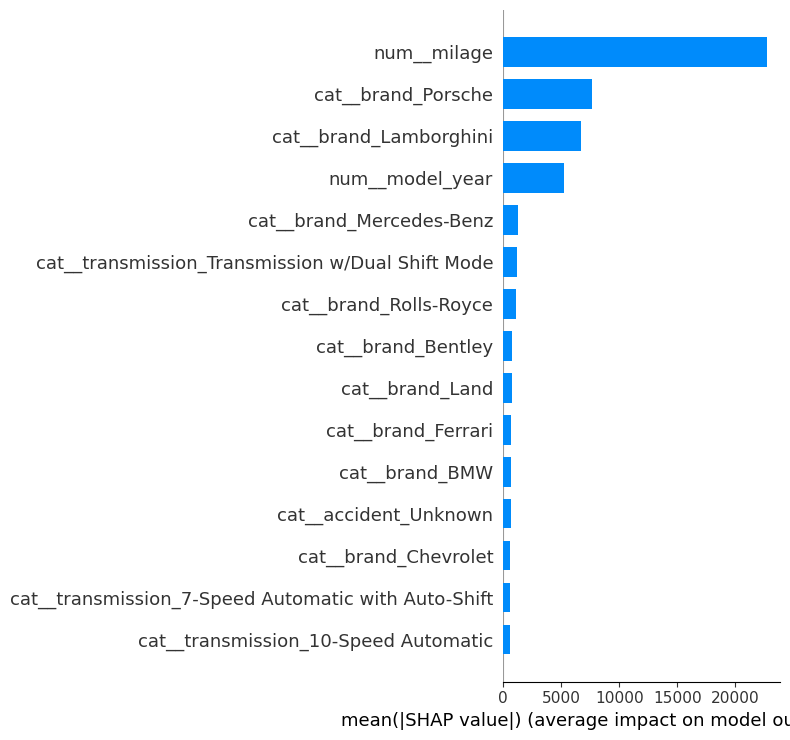

In [44]:

# Random Forest SHAP 분석
explainer = shap.TreeExplainer(fitted_rf)

shap_values = explainer.shap_values(
    X_sample_transformed
)

# 변수 중요도 시각화
shap.summary_plot(
    shap_values,
    X_sample_transformed,
    feature_names=feature_names,
    plot_type='bar',
    max_display=15
)


In [46]:

# 11단계: 최종 테스트 데이터 평가

final_model = rf_tuned

# 테스트 데이터 가격 예측
test_pred = final_model.predict(X_test)

# 성능 계산
test_mae = mean_absolute_error(y_test, test_pred)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_pred)
)

test_r2 = r2_score(y_test, test_pred)

print("=== Final Test Results ===")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R2:", round(test_r2, 4))


=== Final Test Results ===
MAE: 23127.73
RMSE: 153244.8
R2: 0.097


In [48]:

# 테스트 데이터 예측 오차 분석

error_df = X_test.copy()

error_df['Actual_Price'] = y_test
error_df['Predicted_Price'] = test_pred

error_df['Absolute_Error'] = abs(
    error_df['Actual_Price'] -
    error_df['Predicted_Price']
)

# 오차가 가장 큰 차량 10대
display(
    error_df.sort_values(
        'Absolute_Error',
        ascending=False
    ).head(10)
)


,brand,model_year,milage,fuel_type,transmission,accident,Actual_Price,Predicted_Price,Absolute_Error
693,Maserati,2005,32000.0,Gasoline,Transmission w/Dual Shift Mode,At least 1 accident or damage reported,2954083.0,24771.642868,2.929311e+06
229,Bugatti,2011,6330.0,Gasoline,7-Speed Automatic with Auto-Shift,None reported,1950995.0,186723.324034,1.764272e+06
3046,Porsche,2005,4400.0,Gasoline,6-Speed M/T,None reported,1599000.0,158311.072897,1.440689e+06
203,Ford,2005,1897.0,Gasoline,Manual,None reported,429998.0,61703.119749,3.682949e+05
3537,Mercedes-Benz,2017,23567.0,Gasoline,Transmission w/Dual Shift Mode,At least 1 accident or damage reported,215000.0,67807.053667,1.471929e+05
3179,Rolls-Royce,2016,21000.0,Gasoline,A/T,Unknown,217000.0,100867.430475,1.161326e+05
1487,Ford,2021,3596.0,Gasoline,10-Speed Automatic,None reported,56900.0,148314.216323,9.141422e+04
1789,Lexus,2021,915.0,Gasoline,10-Speed A/T,None reported,159000.0,72774.694582,8.622531e+04
432,Mercedes-Benz,2019,47850.0,Gasoline,A/T,At least 1 accident or damage reported,127899.0,43739.566079,8.415943e+04
2003,Porsche,2016,10431.0,Gasoline,7-Speed A/T,None reported,50999.0,132656.948714,8.165795e+04


In [50]:

# 가격 구간별 모델 성능 분석

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 테스트 데이터 평가 결과
analysis_df = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': test_pred
})

# 가격 구간 구분
analysis_df['Price_Group'] = pd.cut(
    analysis_df['Actual'],
    bins=[0, 100000, 500000, np.inf],
    labels=[
        'Under $100K',
        '$100K-$500K',
        'Over $500K'
    ]
)

# 가격 구간별 성능 계산
for group, data in analysis_df.groupby(
    'Price_Group', observed=True
):
    if len(data) == 0:
        continue

    mae = mean_absolute_error(
        data['Actual'], data['Predicted']
    )

    rmse = np.sqrt(mean_squared_error(
        data['Actual'], data['Predicted']
    ))

    print("\n가격 구간:", group)
    print("차량 수:", len(data))
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))



가격 구간: Under $100K
차량 수: 566
MAE: 10545.49
RMSE: 15314.87

가격 구간: $100K-$500K
차량 수: 33
MAE: 55147.83
RMSE: 84475.77

가격 구간: Over $500K
차량 수: 3
MAE: 2044757.32
RMSE: 2142358.84


In [52]:

import joblib
import os

# 최종 학습 모델 저장
joblib.dump(rf_tuned, 'used_car_model.pkl')

# 저장 확인
print("모델 저장 완료!")
print("저장 위치:", os.path.abspath('used_car_model.pkl'))
print("파일 크기:",
      round(os.path.getsize('used_car_model.pkl') / 1024 / 1024, 2),
      "MB")


모델 저장 완료!
저장 위치: /Users/jinseok7381/used_car_model.pkl
파일 크기: 7.08 MB


In [54]:

%pip install streamlit


Note: you may need to restart the kernel to use updated packages.


In [56]:

import streamlit as st

print("Streamlit 설치 완료!")
print("버전:", st.__version__)


Streamlit 설치 완료!
버전: 1.37.1
